# 8. Самостоятельная работа
В качестве самостоятельной работы будет решена задача классификации на основе Spark MLlib с использованием двух моделей машинного обучения. Выбран датасет `Airline Satisfaction Data.csv`. 

In [1]:
from pathlib import Path
from time import perf_counter
import csv
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, functions as F, Window
from pyspark.sql.types import StructType, StructField, LongType, IntegerType, DoubleType, StringType, BooleanType
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.functions import vector_to_array
from pyspark.ml.feature import SQLTransformer, StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from sklearn.metrics import precision_recall_curve, roc_curve, confusion_matrix

spark = (SparkSession.builder
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("WARN")

SEED = 42
ROOT = Path.cwd()
WORK = ROOT / "part2_data"
OUT = ROOT / "part2_results"
WORK.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)

print("Spark:", spark.version)
print("Master:", sc.master)
print("Spark UI:", sc.uiWebUrl)

Spark: 4.2.0
Master: local[*]
Spark UI: http://MSI:4040


In [2]:
AIR_SOURCE = ROOT / "Airline Satisfaction Data.csv"

if not AIR_SOURCE.is_file():
    raise FileNotFoundError(f"Не найден файл: {AIR_SOURCE}")

print("Источник данных:", AIR_SOURCE)
print("Размер:", AIR_SOURCE.stat().st_size // 1024, "KB")

Источник данных: C:\Additional\VirtualMachines\prac5\Airline Satisfaction Data.csv
Размер: 11403 KB


## 1. Загрузка данных в среду выполнения и определение Spark-схемы

In [3]:
AIR_WORK = WORK / "airline_with_id.csv"

if not AIR_WORK.exists():
    with AIR_SOURCE.open("r", encoding="utf-8", newline="") as src, \
    AIR_WORK.open("w", encoding="utf-8", newline="") as dst:
        reader = csv.reader(src)
        writer = csv.writer(dst)
        header = next(reader)
        writer.writerow(["row_id"] + header)
        last_id = 0
        for row_id, row in enumerate(reader, start=1):
            writer.writerow([row_id] + row)
            last_id = row_id
    print(f"Добавлен row_id, записано строк: {last_id}")
else:
    print("Файл уже существует:", AIR_WORK)

Добавлен row_id, записано строк: 129880


In [4]:
air_schema = StructType([
    StructField("row_id", LongType(), False),
    
    # Категориальные
    StructField("Gender", StringType(), False),
    StructField("Customer Type", StringType(), False),
    
    # Числовые
    StructField("Age", IntegerType(), False),
    StructField("Type of Travel", StringType(), False),
    StructField("Class", StringType(), False),
    StructField("Flight Distance", IntegerType(), False),
    
    # Оценки сервиса (1–5, 0 = не оценивалось)
    StructField("Inflight wifi service", IntegerType(), False),
    StructField("Departure/Arrival time convenient", IntegerType(), False),
    StructField("Ease of Online booking", IntegerType(), False),
    StructField("Gate location", IntegerType(), False),
    StructField("Food and drink", IntegerType(), False),
    StructField("Online boarding", IntegerType(), False),
    StructField("Seat comfort", IntegerType(), False),
    StructField("Inflight entertainment", IntegerType(), False),
    StructField("On-board service", IntegerType(), False),
    StructField("Leg room service", IntegerType(), False),
    StructField("Baggage handling", IntegerType(), False),
    StructField("Checkin service", IntegerType(), False),
    StructField("Cleanliness", IntegerType(), False),
    
    # Задержки в минутах
    StructField("Departure Delay in Minutes", IntegerType(), False),
    StructField("Arrival Delay in Minutes", DoubleType(), True),
    
    # Целевая переменная
    StructField("satisfaction", BooleanType(), False),
])

In [5]:
air_raw = (spark.read
    .option("header", True)
    .option("mode", "FAILFAST")
    .option("encoding", "utf-8")
    .schema(air_schema)
    .csv(AIR_WORK.resolve().as_posix())
)

print("Строк:", air_raw.count())

Строк: 129880


In [6]:
air_raw.printSchema()

print("\nЧисло строк:", air_raw.count())
print("Число колонок:", len(air_raw.columns))

air_raw.select("row_id", "Age", "Class", "satisfaction").show(5)

root
 |-- row_id: long (nullable = true)
 |-- Gender: string (nullable = true)
 |-- Customer Type: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Type of Travel: string (nullable = true)
 |-- Class: string (nullable = true)
 |-- Flight Distance: integer (nullable = true)
 |-- Inflight wifi service: integer (nullable = true)
 |-- Departure/Arrival time convenient: integer (nullable = true)
 |-- Ease of Online booking: integer (nullable = true)
 |-- Gate location: integer (nullable = true)
 |-- Food and drink: integer (nullable = true)
 |-- Online boarding: integer (nullable = true)
 |-- Seat comfort: integer (nullable = true)
 |-- Inflight entertainment: integer (nullable = true)
 |-- On-board service: integer (nullable = true)
 |-- Leg room service: integer (nullable = true)
 |-- Baggage handling: integer (nullable = true)
 |-- Checkin service: integer (nullable = true)
 |-- Cleanliness: integer (nullable = true)
 |-- Departure Delay in Minutes: integer (nullable = t

In [7]:
def null_counts(df):
    return df.select(*[
        F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns
    ]).first().asDict()

counts = null_counts(air_raw)
total = air_raw.count()

non_zero = {c: v for c, v in counts.items() if v > 0}
if not non_zero:
    print("Пропусков нет ни в одной колонке.")
else:
    print("Столбцы с пропусками:")
    for c, v in non_zero.items():
        print(f"  {c}: {v} ({v / total:.2%})")

Столбцы с пропусками:
  Arrival Delay in Minutes: 393 (0.30%)


In [8]:
target_dist = (air_raw
    .groupBy("satisfaction")
    .count()
    .orderBy("satisfaction")
    .toPandas())

target_dist["share"] = target_dist["count"] / target_dist["count"].sum()
print(target_dist.to_string(index=False))

 satisfaction  count    share
        False  73452 0.565537
         True  56428 0.434463


## 2. Просмотр распределения ключей объектов для определения схемы разбиения выборки

In [9]:
KEY_CANDIDATES = ["Gender", "Customer Type", "Type of Travel", "Class"]

total = air_raw.count()

for col in KEY_CANDIDATES:
    print(f"\n{col}")
    (air_raw.groupBy(col)
        .count()
        .withColumn("share", F.round(F.col("count") / F.lit(total), 4))
        .orderBy(F.desc("count"))
        .show(truncate=False))


Gender
+------+-----+------+
|Gender|count|share |
+------+-----+------+
|Female|65899|0.5074|
|Male  |63981|0.4926|
+------+-----+------+


Customer Type
+-----------------+------+------+
|Customer Type    |count |share |
+-----------------+------+------+
|Loyal Customer   |106100|0.8169|
|disloyal Customer|23780 |0.1831|
+-----------------+------+------+


Type of Travel
+---------------+-----+------+
|Type of Travel |count|share |
+---------------+-----+------+
|Business travel|89693|0.6906|
|Personal Travel|40187|0.3094|
+---------------+-----+------+


Class
+--------+-----+------+
|Class   |count|share |
+--------+-----+------+
|Business|62160|0.4786|
|Eco     |58309|0.4489|
|Eco Plus|9411 |0.0725|
+--------+-----+------+



In [10]:
import time

feature_cols = [c for c in air_raw.columns
                if c not in ("row_id", "satisfaction")]

t0 = time.perf_counter()
dups_count = (air_raw
    .groupBy(*feature_cols)
    .count()
    .filter(F.col("count") > 1)
    .agg(F.sum("count").alias("duplicated_rows"),
         F.count("*").alias("groups_with_dups"))
    .first())
dt = time.perf_counter() - t0

print(f"Групп с дубликатами признаков: {dups_count['groups_with_dups']}")
print(f"Строк, входящих в такие группы: {dups_count['duplicated_rows']}")
print(f"Время: {dt:.1f} с")

Групп с дубликатами признаков: 0
Строк, входящих в такие группы: None
Время: 1.7 с


In [11]:
def crosstab_with_target(df, col):
    total = df.count()
    result = (df.groupBy(col)
        .agg(
            F.count("*").alias("n"),
            F.sum(F.col("satisfaction").cast("int")).alias("satisfied"),
        )
        .withColumn("share_total", F.round(F.col("n") / F.lit(total), 4))
        .withColumn("satisfaction_rate",
                    F.round(F.col("satisfied") / F.col("n"), 4))
        .orderBy(F.desc("satisfaction_rate")))
    print(f"\n{col} × satisfaction")
    result.show(truncate=False)

for col in KEY_CANDIDATES:
    crosstab_with_target(air_raw, col)


Gender × satisfaction
+------+-----+---------+-----------+-----------------+
|Gender|n    |satisfied|share_total|satisfaction_rate|
+------+-----+---------+-----------+-----------------+
|Male  |63981|28159    |0.4926     |0.4401           |
|Female|65899|28269    |0.5074     |0.429            |
+------+-----+---------+-----------+-----------------+


Customer Type × satisfaction
+-----------------+------+---------+-----------+-----------------+
|Customer Type    |n     |satisfied|share_total|satisfaction_rate|
+-----------------+------+---------+-----------+-----------------+
|Loyal Customer   |106100|50728    |0.8169     |0.4781           |
|disloyal Customer|23780 |5700     |0.1831     |0.2397           |
+-----------------+------+---------+-----------+-----------------+


Type of Travel × satisfaction
+---------------+-----+---------+-----------+-----------------+
|Type of Travel |n    |satisfied|share_total|satisfaction_rate|
+---------------+-----+---------+-----------+---------

## 3. Разбиение набора данных на тренировочный, валидационный и тестовый наборы, опираясь на смысл выборки (независимые объекты / временные данные).

In [12]:
air = air_raw.withColumn("label", F.col("satisfaction").cast("double"))

print("Распределение label:")
air.groupBy("label").count().orderBy("label").show()

Распределение label:
+-----+-----+
|label|count|
+-----+-----+
|  0.0|73452|
|  1.0|56428|
+-----+-----+



In [13]:
order_key = F.sha2(
    F.concat_ws(":", F.col("row_id").cast("string"), F.lit(str(SEED))),
    256
)

rank_window = Window.partitionBy("label").orderBy(order_key, "row_id")
class_window = Window.partitionBy("label")

air_split = (air
    .withColumn("_rank", F.row_number().over(rank_window))
    .withColumn("_size", F.count("*").over(class_window))
    .withColumn("split",
                F.when(F.col("_rank") <= F.floor(F.col("_size") * 0.60), "train")
                    .when(F.col("_rank") <= F.floor(F.col("_size") * 0.80), "valid")
                    .otherwise("test"))
    .drop("_rank", "_size")
    .cache())

air_split.groupBy("split", "label").count().orderBy("split", "label").show()

+-----+-----+-----+
|split|label|count|
+-----+-----+-----+
| test|  0.0|14691|
| test|  1.0|11286|
|train|  0.0|44071|
|train|  1.0|33856|
|valid|  0.0|14690|
|valid|  1.0|11286|
+-----+-----+-----+



In [14]:
air_train = air_split.filter("split = 'train'").drop("split").cache()
air_valid = air_split.filter("split = 'valid'").drop("split").cache()
air_test = air_split.filter("split = 'test'").drop("split").cache()

n_train = air_train.count()
n_valid = air_valid.count()
n_test = air_test.count()
n_total = n_train + n_valid + n_test

print(f"train: {n_train:>7}  ({n_train/n_total:.2%})")
print(f"valid: {n_valid:>7}  ({n_valid/n_total:.2%})")
print(f"test:  {n_test:>7}  ({n_test/n_total:.2%})")
print(f"итого: {n_total:>7}")

train:   77927  (60.00%)
valid:   25976  (20.00%)
test:    25977  (20.00%)
итого:  129880


In [15]:
assert n_total == 129880, f"Потеря строк: {n_total} != 129880"
print("OK: сумма частей равна исходному размеру")

OK: сумма частей равна исходному размеру


In [16]:
train_ids = set(r["row_id"] for r in air_train.select("row_id").collect())
valid_ids = set(r["row_id"] for r in air_valid.select("row_id").collect())
test_ids = set(r["row_id"] for r in air_test.select("row_id").collect())

inter_tv = len(train_ids & valid_ids)
inter_tt = len(train_ids & test_ids)
inter_vt = len(valid_ids & test_ids)
print(f"Пересечения row_id: train∩valid={inter_tv}, train∩test={inter_tt}, valid∩test={inter_vt}")
assert inter_tv == 0 and inter_tt == 0 and inter_vt == 0, "Пересечение частей!"
print("OK: пересечений нет")

Пересечения row_id: train∩valid=0, train∩test=0, valid∩test=0
OK: пересечений нет


In [17]:
share_orig = (air.select(F.avg("label")).first()[0])

for name, df in [("train", air_train), ("valid", air_valid), ("test", air_test)]:
    n = df.count()
    pos = df.filter(F.col("label") == 1.0).count()
    print(f"{name:5s}  Positive share = {pos/n:.4f}  (исходное: {share_orig:.4f})")

train  Positive share = 0.4345  (исходное: 0.4345)
valid  Positive share = 0.4345  (исходное: 0.4345)
test   Positive share = 0.4345  (исходное: 0.4345)


In [18]:
print("Колонки train:", air_train.columns)
print("Тип label:", air_train.schema["label"].dataType)
print("Тип satisfaction:", air_train.schema["satisfaction"].dataType)

Колонки train: ['row_id', 'Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction', 'label']
Тип label: DoubleType()
Тип satisfaction: BooleanType()


## 4. Просмотр распределений предикторов и целевой переменной

In [19]:
NUMERIC_COLS = ["Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"]

air_train.select(*NUMERIC_COLS).describe().show(truncate=False)

+-------+------------------+------------------+--------------------------+------------------------+
|summary|Age               |Flight Distance   |Departure Delay in Minutes|Arrival Delay in Minutes|
+-------+------------------+------------------+--------------------------+------------------------+
|count  |77927             |77927             |77927                     |77690                   |
|mean   |39.39861665404802 |1191.4255906168594|14.614036213379189        |15.019050070794181      |
|stddev |15.113112334965617|996.5786305761392 |37.63648082170992         |38.00817101028292       |
|min    |7                 |31                |0                         |0.0                     |
|max    |85                |4983              |1592                      |1584.0                  |
+-------+------------------+------------------+--------------------------+------------------------+



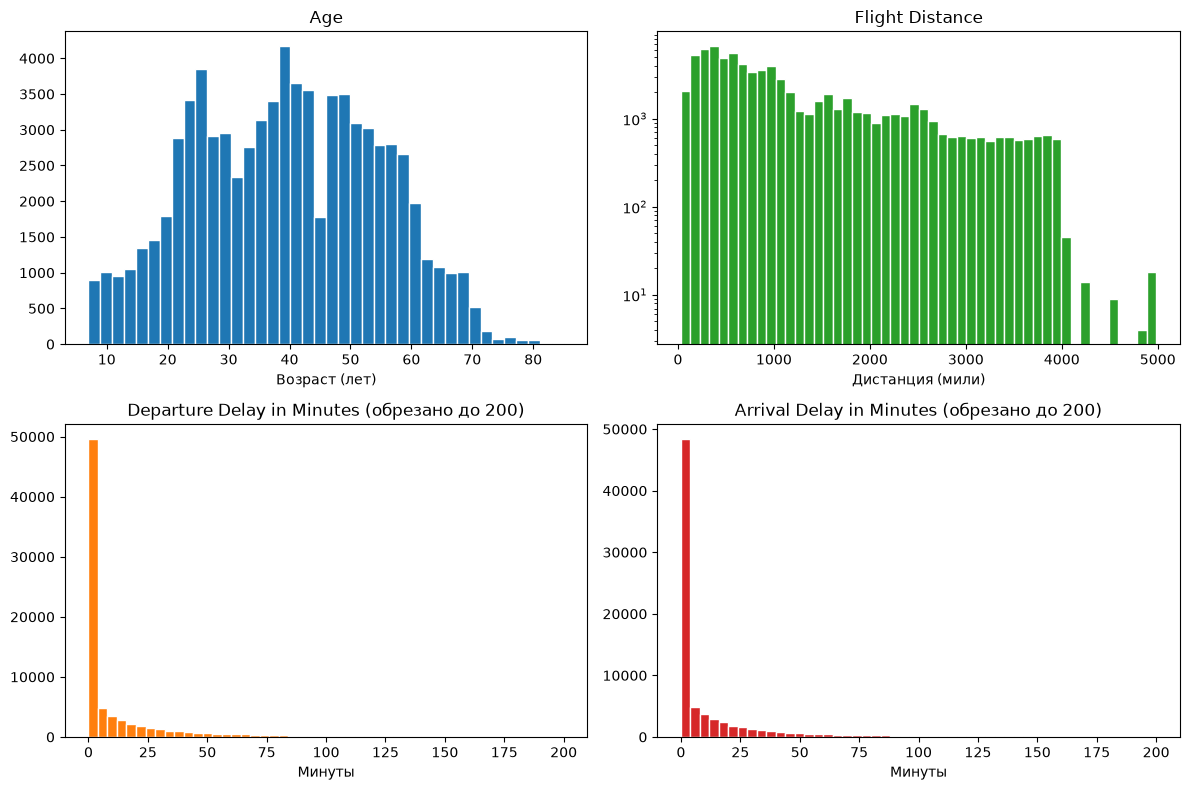

In [20]:
local_num = air_train.select("Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes", "label").toPandas()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].hist(local_num["Age"], bins=40, color="tab:blue", edgecolor="white")
axes[0, 0].set_title("Age")
axes[0, 0].set_xlabel("Возраст (лет)")

axes[0, 1].hist(local_num["Flight Distance"], bins=50, color="tab:green", edgecolor="white")
axes[0, 1].set_title("Flight Distance")
axes[0, 1].set_xlabel("Дистанция (мили)")
axes[0, 1].set_yscale("log")

d = local_num["Departure Delay in Minutes"]
axes[1, 0].hist(d[d <= 200], bins=50, color="tab:orange", edgecolor="white")
axes[1, 0].set_title("Departure Delay in Minutes (обрезано до 200)")
axes[1, 0].set_xlabel("Минуты")

d = local_num["Arrival Delay in Minutes"].dropna()
axes[1, 1].hist(d[d <= 200], bins=50, color="tab:red", edgecolor="white")
axes[1, 1].set_title("Arrival Delay in Minutes (обрезано до 200)")
axes[1, 1].set_xlabel("Минуты")

plt.tight_layout()
plt.savefig(OUT / "numeric_distributions.png", dpi=160)
plt.show()

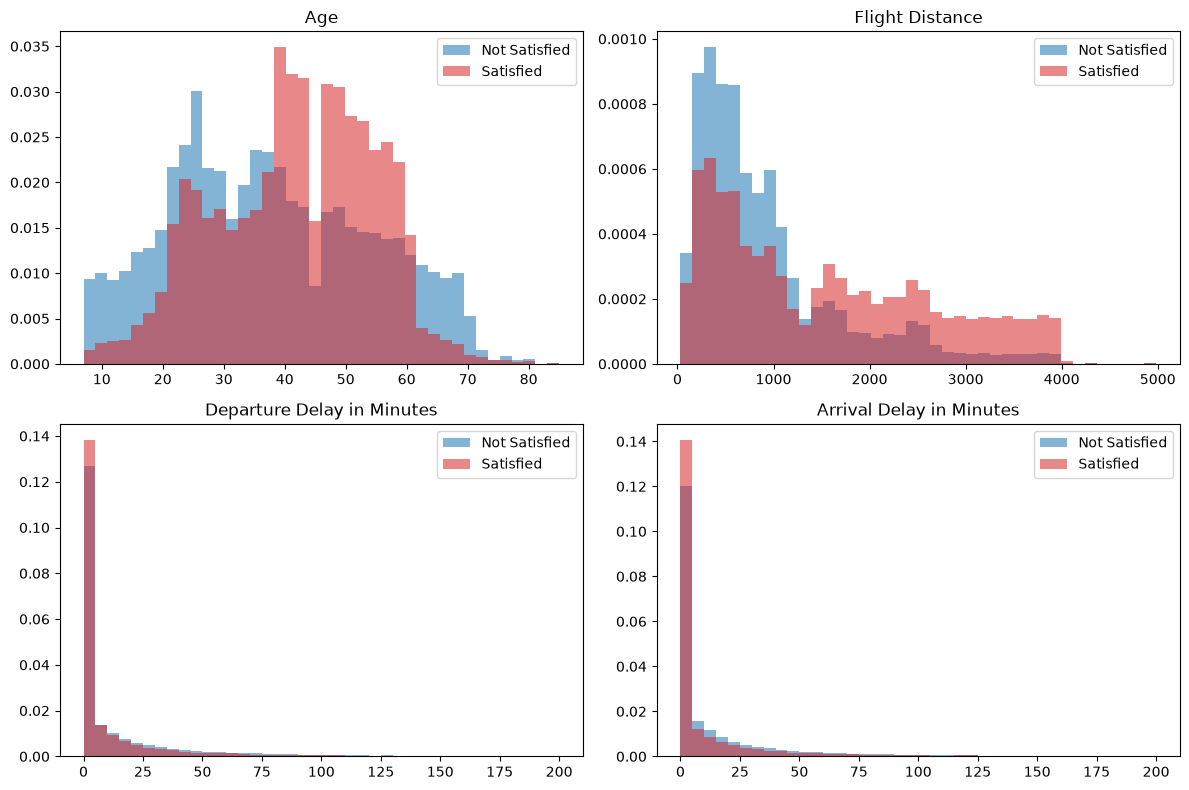

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, ["Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"]):
    values_neg = local_num.loc[local_num["label"] == 0.0, col].dropna()
    values_pos = local_num.loc[local_num["label"] == 1.0, col].dropna()

    if "Delay" in col:
        values_neg = values_neg[values_neg <= 200]
        values_pos = values_pos[values_pos <= 200]

    ax.hist(values_neg, bins=40, alpha=0.55, label="Not Satisfied",
            color="tab:blue", density=True)
    ax.hist(values_pos, bins=40, alpha=0.55, label="Satisfied",
            color="tab:red", density=True)
    ax.set_title(col)
    ax.legend()

plt.tight_layout()
plt.savefig(OUT / "numeric_distributions_by_class.png", dpi=160)
plt.show()

In [22]:
RATING_COLS = ["Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking",
               "Gate location", "Food and drink", "Online boarding", "Seat comfort", "Inflight entertainment",
               "On-board service", "Leg room service", "Baggage handling", "Checkin service", "Cleanliness"
]

summary = (air_train
    .groupBy("label")
    .agg(*[F.round(F.avg(c), 3).alias(c) for c in RATING_COLS])
    .orderBy("label")
    .toPandas()
    .set_index("label"))

print("Средние оценки по классам:")
print(summary.T.to_string())

Средние оценки по классам:
label                                0.0    1.0
Inflight wifi service              2.403  3.163
Departure/Arrival time convenient  3.140  2.970
Ease of Online booking             2.553  3.035
Gate location                      2.988  2.973
Food and drink                     2.959  3.517
Online boarding                    2.661  4.024
Seat comfort                       3.041  3.966
Inflight entertainment             2.891  3.966
On-board service                   3.020  3.866
Leg room service                   2.990  3.830
Baggage handling                   3.375  3.968
Checkin service                    3.049  3.650
Cleanliness                        2.932  3.742


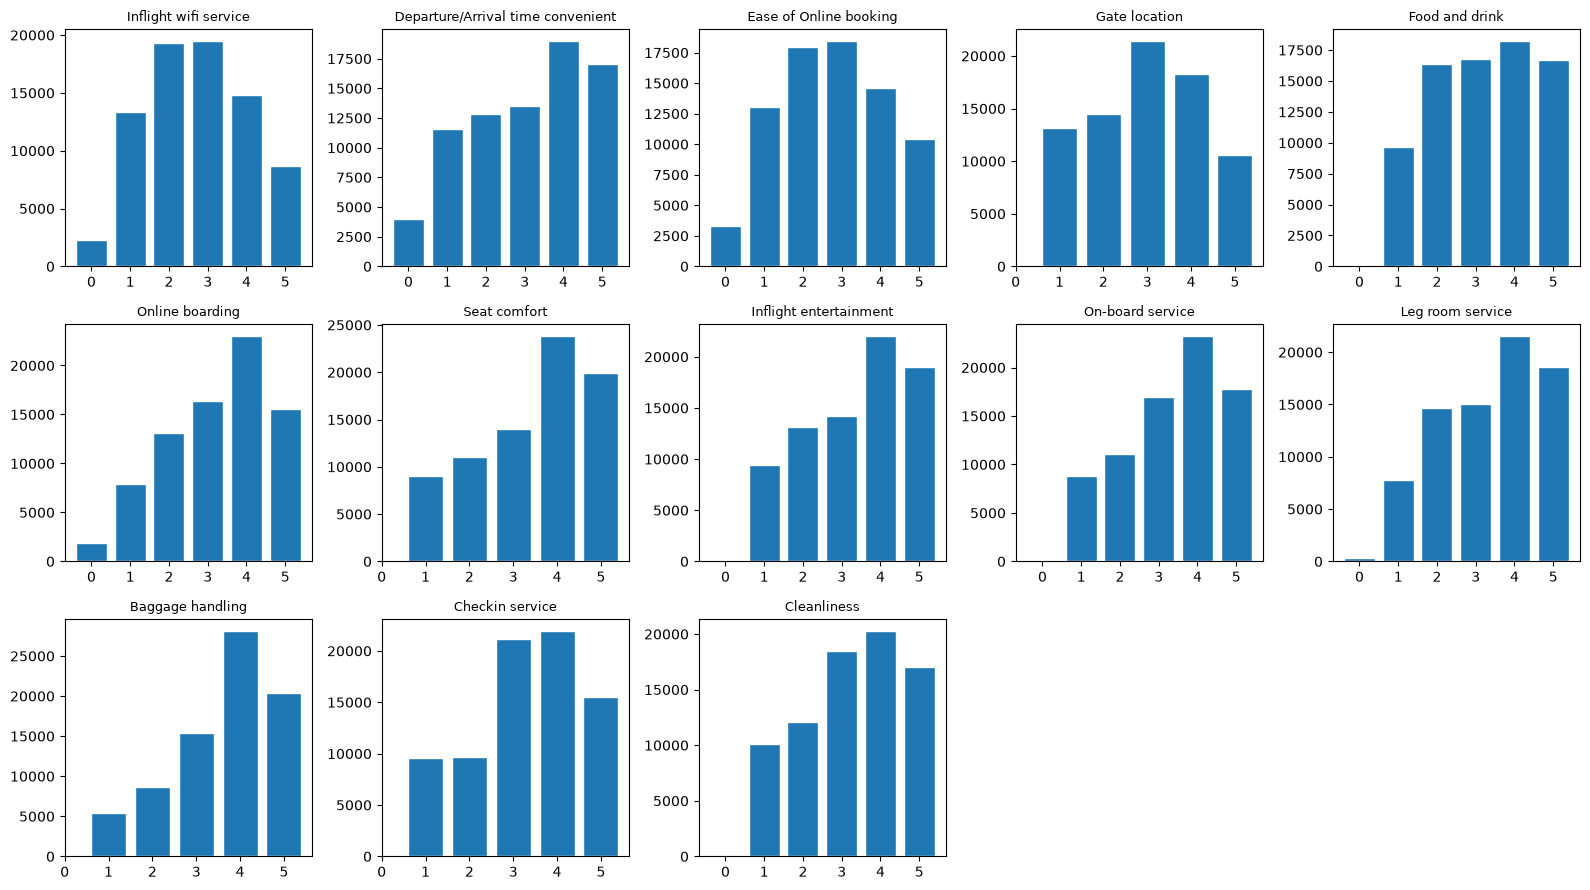

In [23]:
local_ratings = air_train.select(*RATING_COLS).toPandas()

fig, axes = plt.subplots(3, 5, figsize=(16, 9))
for ax, col in zip(axes.flat, RATING_COLS):
    counts = local_ratings[col].value_counts().sort_index()
    ax.bar(counts.index, counts.values, color="tab:blue", edgecolor="white")
    ax.set_title(col, fontsize=9)
    ax.set_xticks([0, 1, 2, 3, 4, 5])
axes.flat[-1].axis("off")
axes.flat[-2].axis("off")
plt.tight_layout()
plt.savefig(OUT / "rating_distributions.png", dpi=160)
plt.show()

In [24]:
def stats_by_label(df, col):
    return (df.groupBy("label")
        .agg(F.round(F.avg(col), 2).alias("mean"),
             F.round(F.expr(f"percentile_approx(`{col}`, 0.5)"), 2).alias("median"),
             F.round(F.stddev(col), 2).alias("std"))
            .orderBy("label")
    .toPandas()
    .assign(feature=col)
    .set_index(["feature", "label"]))

rows = [stats_by_label(air_train, c) for c in NUMERIC_COLS]
print(pd.concat(rows).to_string())

                                     mean  median      std
feature                    label                          
Age                        0.0      37.64    36.0    16.45
                           1.0      41.69    43.0    12.81
Flight Distance            0.0     928.20   674.0   788.48
                           1.0    1534.07  1265.0  1126.56
Departure Delay in Minutes 0.0      16.29     0.0    40.02
                           1.0      12.43     0.0    34.16
Arrival Delay in Minutes   0.0      16.99     0.0    40.39
                           1.0      12.45     0.0    34.50


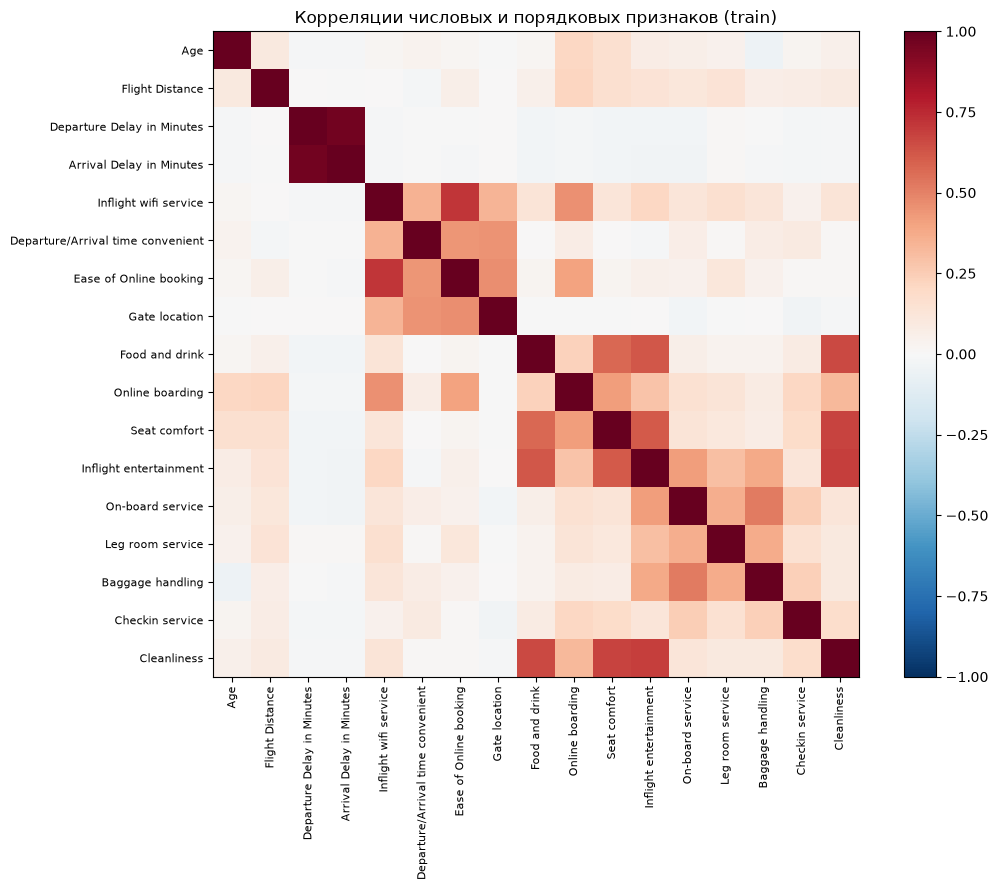

Топ-5 положительных корреляций:
  +0.964  Departure Delay in Minutes ↔ Arrival Delay in Minutes
  +0.718  Inflight wifi service ↔ Ease of Online booking
  +0.694  Inflight entertainment ↔ Cleanliness
  +0.677  Seat comfort ↔ Cleanliness
  +0.660  Food and drink ↔ Cleanliness


In [25]:
CORR_COLS = ["Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"] + RATING_COLS

local_corr = air_train.select(*CORR_COLS).toPandas()
corr = local_corr.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticklabels(corr.columns, fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.04)
ax.set_title("Корреляции числовых и порядковых признаков (train)")
plt.tight_layout()
plt.savefig(OUT / "correlation_matrix.png", dpi=160)
plt.show()

import itertools
pairs = [(corr.iloc[i, j], corr.columns[i], corr.columns[j])
         for i, j in itertools.combinations(range(len(corr)), 2)]
pairs.sort(reverse=True)
print("Топ-5 положительных корреляций:")
for v, a, b in pairs[:5]:
    print(f"  {v:+.3f}  {a} ↔ {b}")

## 5. Выбор предикторов и целевой переменной прогнозирования, определение точек возможной утечки данных.

In [26]:
CAT_COLS = ["Gender", "Customer Type", "Type of Travel", "Class"]

RATING_COLS = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness",
]

NUM_BASE  = ["Age", "Flight Distance"]
DELAY_COL = "Departure Delay in Minutes"

LOG_SOURCE = [DELAY_COL]
LOG_OUTPUT = ["log_" + DELAY_COL]

In [27]:
RAW_A = NUM_BASE + [DELAY_COL] + RATING_COLS + CAT_COLS
RAW_B = NUM_BASE + RATING_COLS + CAT_COLS

for name, cols in [("A (с задержкой)", RAW_A), ("B (без задержки)", RAW_B)]:
    n_null = air_train.select(*[
        F.sum(F.col(c).isNull().cast("int")).alias(c) for c in cols
    ]).first().asDict()
    non_zero = {c: v for c, v in n_null.items() if v > 0}
    total_null = sum(non_zero.values())
    print(f"Сценарий {name}: {len(cols)} признаков, пропусков = {total_null}  ({non_zero if non_zero else 'нет'})")

print("\nУникальные значения label:", sorted(r["label"] for r in air_train.select("label").distinct().collect()))

Сценарий A (с задержкой): 20 признаков, пропусков = 0  (нет)
Сценарий B (без задержки): 19 признаков, пропусков = 0  (нет)

Уникальные значения label: [0.0, 1.0]


## 6. Построение и оценка параметров моделей машинного обучения, подбор оптимальных гиперпараметров либо с помощью кросс-валидации, либо минимизируя функцию стоимости на валидационной выборке.

In [28]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator

def binary_metrics(pred, threshold=0.5, ranking=True):
    decision = F.col("score") >= F.lit(float(threshold))
    y = F.col("label") == 1.0
    values = pred.agg(
        F.sum((decision &  y).cast("long")).alias("tp"),
        F.sum((decision & ~y).cast("long")).alias("fp"),
        F.sum((~decision &  y).cast("long")).alias("fn"),
        F.sum((~decision & ~y).cast("long")).alias("tn"),
    ).first().asDict()
    tp, fp, fn, tn = values["tp"], values["fp"], values["fn"], values["tn"]
    n = tp + fp + fn + tn
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall    = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    result = {
        "accuracy": (tp + tn) / n,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
    }
    if ranking and "score" in pred.columns:
        for m in ["areaUnderROC", "areaUnderPR"]:
            result[m] = BinaryClassificationEvaluator(
                labelCol="label", rawPredictionCol="score",
                metricName=m).evaluate(pred)
    return result

In [29]:
pos_rate_train = air_train.agg(F.avg("label")).first()[0]
print(f"Доля положительного класса в train: {pos_rate_train:.4f}")

baseline_constant = (air_valid
    .withColumn("score", F.lit(float(pos_rate_train)))
    .withColumn("prediction", F.lit(0.0)))

print("Baseline «всегда большинство» на valid:")
print(binary_metrics(baseline_constant, threshold=0.5, ranking=True))

Доля положительного класса в train: 0.4345
Baseline «всегда большинство» на valid:
{'accuracy': 0.5655220203264552, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'tp': 0, 'fp': 0, 'fn': 11286, 'tn': 14690, 'areaUnderROC': 0.5, 'areaUnderPR': 0.4344779796735448}


In [30]:
class_rate = (air_train
    .groupBy("Class")
    .agg(F.avg("label").alias("class_rate"))
    .toPandas())
print(class_rate.to_string(index=False))

class_rate_df = spark.createDataFrame(class_rate)
baseline_class = (air_valid
    .join(class_rate_df, "Class", "left")
    .withColumn("score", F.col("class_rate"))
    .withColumn("prediction", (F.col("class_rate") >= 0.5).cast("double"))
    .drop("class_rate"))

print("\nBaseline «правило по Class» на valid:")
print(binary_metrics(baseline_class, threshold=0.5, ranking=True))

   Class  class_rate
Eco Plus    0.252174
Business    0.695556
     Eco    0.186627

Baseline «правило по Class» на valid:
{'accuracy': 0.7507314444102248, 'precision': 0.693508165071193, 'recall': 0.763866737550948, 'f1': 0.7269890795631826, 'tp': 8621, 'fp': 3810, 'fn': 2665, 'tn': 10880, 'areaUnderROC': 0.7554567084143238, 'areaUnderPR': 0.6610488260311178}


In [31]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    SQLTransformer, StringIndexer, OneHotEncoder,
    VectorAssembler, StandardScaler,
)
from pyspark.ml.classification import LogisticRegression

def airline_lr_pipeline(include_delay=True, reg_param=0.05):
    if include_delay:
        log_stage = SQLTransformer(
            statement=f"SELECT *, log1p(`{DELAY_COL}`) AS `{LOG_OUTPUT[0]}` FROM __THIS__"
        )
        numeric_after_log = NUM_BASE + LOG_OUTPUT + RATING_COLS
        stages = [log_stage]
    else:
        numeric_after_log = NUM_BASE + RATING_COLS
        stages = []

    idx_cols = [c + "_idx" for c in CAT_COLS]
    ohe_cols = [c + "_ohe" for c in CAT_COLS]

    indexer = StringIndexer(
        inputCols=CAT_COLS, outputCols=idx_cols,
        handleInvalid="keep", stringOrderType="alphabetAsc",
    )
    encoder = OneHotEncoder(
        inputCols=idx_cols, outputCols=ohe_cols,
        handleInvalid="keep", dropLast=False,
    )
    assembler = VectorAssembler(
        inputCols=numeric_after_log + ohe_cols,
        outputCol="features_raw",
    )
    scaler = StandardScaler(
        inputCol="features_raw", outputCol="features",
        withMean=False, withStd=True,
    )
    lr = LogisticRegression(
        maxIter=100, regParam=reg_param, elasticNetParam=0.0,
        standardization=False,
    )
    stages += [indexer, encoder, assembler, scaler, lr]
    return Pipeline(stages=stages)

In [32]:
from pyspark.ml.classification import RandomForestClassifier

def airline_rf_pipeline(include_delay=True, num_trees=80, max_depth=12):
    if include_delay:
        numeric = NUM_BASE + [DELAY_COL] + RATING_COLS
    else:
        numeric = NUM_BASE + RATING_COLS

    idx_cols = [c + "_idx" for c in CAT_COLS]
    ohe_cols = [c + "_ohe" for c in CAT_COLS]

    indexer = StringIndexer(
        inputCols=CAT_COLS, outputCols=idx_cols,
        handleInvalid="keep", stringOrderType="alphabetAsc",
    )
    encoder = OneHotEncoder(
        inputCols=idx_cols, outputCols=ohe_cols,
        handleInvalid="keep", dropLast=False,
    )
    assembler = VectorAssembler(
        inputCols=numeric + ohe_cols,
        outputCol="features",
    )
    rf = RandomForestClassifier(
        numTrees=num_trees, maxDepth=max_depth, maxBins=64,
        featureSubsetStrategy="sqrt", seed=SEED,
    )
    return Pipeline(stages=[indexer, encoder, assembler, rf])

In [33]:
def scores(model, df):
    return (model.transform(df)
        .withColumn("score", vector_to_array("probability")[1])
        .select("row_id", "label", "score"))

In [34]:
import time

results = []
models = {}

for reg in [0.01, 0.1]:
    name = f"LR(reg={reg})"
    sc.setJobGroup("AIR_LR", name)
    t0 = time.perf_counter()
    model = airline_lr_pipeline(include_delay=True, reg_param=reg).fit(air_train)
    fit_s = time.perf_counter() - t0
    pred = scores(model, air_valid).cache()
    pred.count()
    m = binary_metrics(pred)
    results.append({"model": name, "fit_s": round(fit_s, 1), **m})
    models[name] = (model, pred)

for nt, md in [(50, 8), (100, 12)]:
    name = f"RF(trees={nt}, depth={md})"
    sc.setJobGroup("AIR_RF", name)
    t0 = time.perf_counter()
    model = airline_rf_pipeline(include_delay=True, num_trees=nt, max_depth=md).fit(air_train)
    fit_s = time.perf_counter() - t0
    pred = scores(model, air_valid).cache()
    pred.count()
    m = binary_metrics(pred)
    results.append({"model": name, "fit_s": round(fit_s, 1), **m})
    models[name] = (model, pred)

results.append({"model": "Baseline: константа", "fit_s": 0.0, **binary_metrics(baseline_constant)})
results.append({"model": "Baseline: правило по Class", "fit_s": 0.0, **binary_metrics(baseline_class)})

val_table = pd.DataFrame(results).sort_values("areaUnderPR", ascending=False)
cols = ["model", "fit_s", "accuracy", "precision", "recall", "f1", "areaUnderROC", "areaUnderPR"]
print(val_table[cols].round(4).to_string(index=False))

                     model  fit_s  accuracy  precision  recall     f1  areaUnderROC  areaUnderPR
   RF(trees=100, depth=12)   61.7    0.9500     0.9492  0.9350 0.9420        0.9896       0.9884
     RF(trees=50, depth=8)   16.0    0.9354     0.9325  0.9177 0.9250        0.9819       0.9785
              LR(reg=0.01)   18.8    0.8741     0.8695  0.8356 0.8522        0.9275       0.9306
               LR(reg=0.1)    8.2    0.8688     0.8683  0.8228 0.8449        0.9232       0.9265
Baseline: правило по Class    0.0    0.7507     0.6935  0.7639 0.7270        0.7555       0.6610
       Baseline: константа    0.0    0.5655     0.0000  0.0000 0.0000        0.5000       0.4345


In [35]:
learned = val_table[~val_table["model"].str.startswith("Baseline")]
best_name = learned.iloc[0]["model"]
best_model, best_pred_valid = models[best_name]

print("Лучшая модель по PR-AUC:", best_name)
print("PR-AUC:", round(learned.iloc[0]["areaUnderPR"], 4))
print("Accuracy:", round(learned.iloc[0]["accuracy"], 4))

Лучшая модель по PR-AUC: RF(trees=100, depth=12)
PR-AUC: 0.9884
Accuracy: 0.95


In [36]:
rf_cfg = best_name.replace("RF(trees=", "").replace(")", "").split(", depth=")
n_trees, depth = int(rf_cfg[0]), int(rf_cfg[1])

rf_no_delay = airline_rf_pipeline(
    include_delay=False, num_trees=n_trees, max_depth=depth,
).fit(air_train)

pred_no_delay = scores(rf_no_delay, air_valid).cache()
pred_no_delay.count()

print("RF с задержкой:", binary_metrics(best_pred_valid)["areaUnderPR"])
print("RF без задержки:", binary_metrics(pred_no_delay)["areaUnderPR"])

RF с задержкой: 0.9883693488644335
RF без задержки: 0.9882114066070997


## 7. Оценка качества модели на тестовых данных с использованием метрики качества модели и визуализация работы модели на тестовой выборке.

In [37]:
from sklearn.metrics import precision_recall_curve

valid_pd = best_pred_valid.toPandas()
precision, recall, thresholds = precision_recall_curve(valid_pd["label"], valid_pd["score"])

f1_scores = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
best_idx = int(np.nanargmax(f1_scores[:-1]))
BEST_THRESHOLD = float(thresholds[best_idx])

print(f"Порог по максимуму F1 на valid: {BEST_THRESHOLD:.4f}")
print(f"F1 при этом пороге: {f1_scores[best_idx]:.4f}")
print(f"Precision при этом пороге: {precision[best_idx]:.4f}")
print(f"Recall при этом пороге: {recall[best_idx]:.4f}")

Порог по максимуму F1 на valid: 0.5515
F1 при этом пороге: 0.9431
Precision при этом пороге: 0.9572
Recall при этом пороге: 0.9295


In [38]:
test_scores = scores(best_model, air_test).cache()
test_scores.count()

print("Метрики на test при пороге из valid:")
test_metrics = binary_metrics(test_scores, threshold=BEST_THRESHOLD)
for k, v in test_metrics.items():
    if isinstance(v, float):
        print(f"  {k} = {v:.4f}")
    else:
        print(f"  {k} = {v}")

Метрики на test при пороге из valid:
  accuracy = 0.9553
  precision = 0.9599
  recall = 0.9362
  f1 = 0.9479
  tp = 10566
  fp = 441
  fn = 720
  tn = 14250
  areaUnderROC = 0.9911
  areaUnderPR = 0.9901


In [39]:
compare = []
for name, thr in [("Порог 0.5", 0.5), (f"Порог {BEST_THRESHOLD:.3f}", BEST_THRESHOLD)]:
    m = binary_metrics(test_scores, threshold=thr)
    compare.append({
        "scenario": name,
        "accuracy": round(m["accuracy"], 4),
        "precision": round(m["precision"], 4),
        "recall": round(m["recall"], 4),
        "f1": round(m["f1"], 4),
        "tp": m["tp"],
        "fp": m["fp"],
        "fn": m["fn"],
        "tn": m["tn"],
    })

print(pd.DataFrame(compare).to_string(index=False))

   scenario  accuracy  precision  recall     f1    tp  fp  fn    tn
  Порог 0.5    0.9547     0.9534  0.9417 0.9475 10628 519 658 14172
Порог 0.552    0.9553     0.9599  0.9362 0.9479 10566 441 720 14250


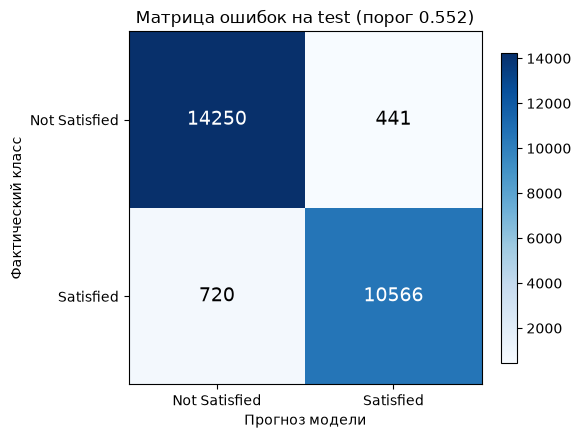

TP=10566  FP=441  FN=720  TN=14250


In [40]:
from sklearn.metrics import confusion_matrix

test_pd = test_scores.toPandas()
test_pred = (test_pd["score"] >= BEST_THRESHOLD).astype(int)
cm = confusion_matrix(test_pd["label"].astype(int), test_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["Not Satisfied", "Satisfied"])
ax.set_yticks([0, 1], ["Not Satisfied", "Satisfied"])
ax.set_xlabel("Прогноз модели")
ax.set_ylabel("Фактический класс")
ax.set_title(f"Матрица ошибок на test (порог {BEST_THRESHOLD:.3f})")
plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.savefig(OUT / "test_confusion_matrix.png", dpi=160)
plt.show()

print(f"TP={cm[1,1]}  FP={cm[0,1]}  FN={cm[1,0]}  TN={cm[0,0]}")

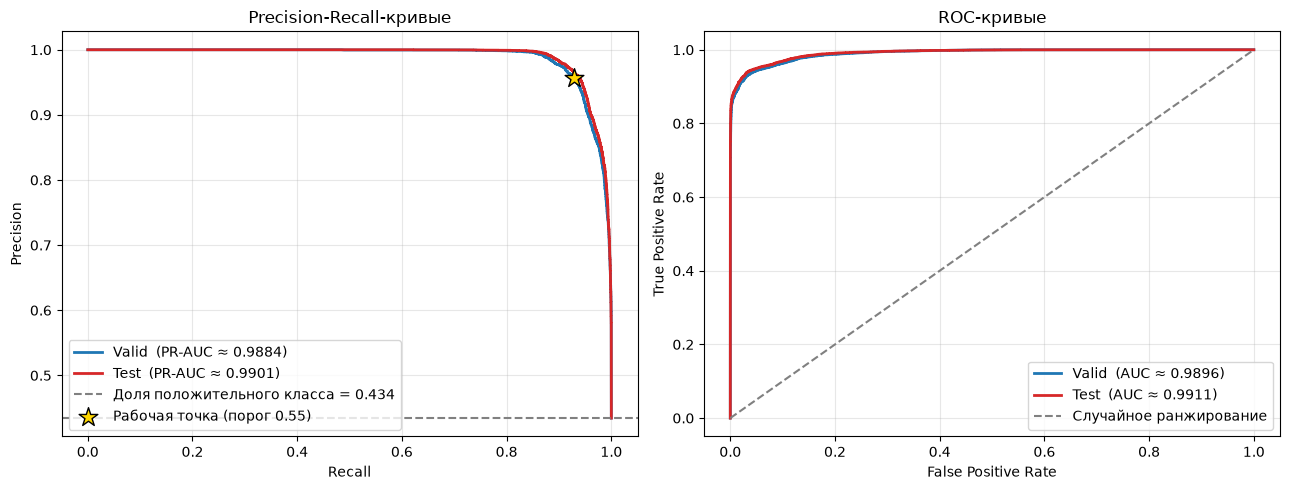

In [41]:
from sklearn.metrics import roc_curve, auc

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
for label, pdf, color in [
    ("Valid", valid_pd, "tab:blue"),
    ("Test",  test_pd,  "tab:red"),
]:
    p, r, _ = precision_recall_curve(pdf["label"], pdf["score"])
    pr_auc = auc(r, p)
    ax.plot(r, p, label=f"{label}  (PR-AUC ≈ {pr_auc:.4f})", color=color, linewidth=2)

ax.axhline(pos_rate_train, linestyle="--", color="gray", label=f"Доля положительного класса = {pos_rate_train:.3f}")
ax.scatter([recall[best_idx]], [precision[best_idx]], marker="*", s=200, color="gold", edgecolors="black", label=f"Рабочая точка (порог {BEST_THRESHOLD:.2f})", zorder=5)
ax.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall-кривые")
ax.grid(alpha=0.3)
ax.legend(loc="lower left")

ax = axes[1]
for label, pdf, color in [
    ("Valid", valid_pd, "tab:blue"),
    ("Test", test_pd, "tab:red"),
]:
    fpr, tpr, _ = roc_curve(pdf["label"], pdf["score"])
    ax.plot(fpr, tpr, label=f"{label}  (AUC ≈ {auc(fpr, tpr):.4f})", color=color, linewidth=2)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Случайное ранжирование")
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC-кривые")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig(OUT / "test_pr_roc.png", dpi=160)
plt.show()

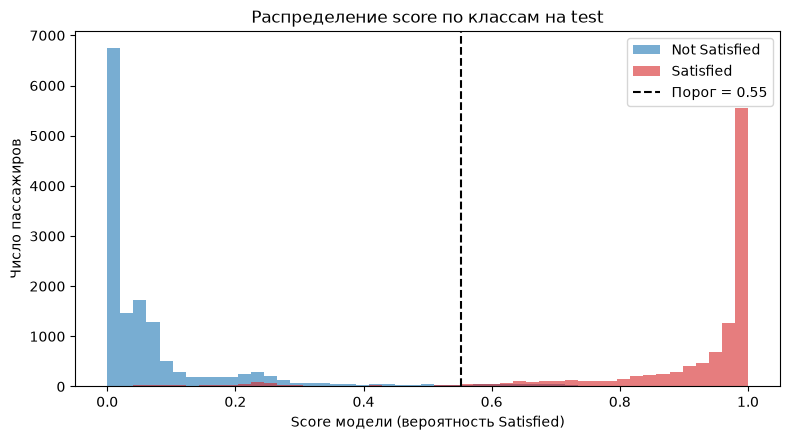

In [42]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(0, 1, 50)
ax.hist(test_pd.loc[test_pd["label"] == 0.0, "score"], bins=bins, alpha=0.6, label="Not Satisfied", color="tab:blue")
ax.hist(test_pd.loc[test_pd["label"] == 1.0, "score"], bins=bins, alpha=0.6, label="Satisfied", color="tab:red")
ax.axvline(BEST_THRESHOLD, color="black", linestyle="--", label=f"Порог = {BEST_THRESHOLD:.2f}")
ax.set(xlabel="Score модели (вероятность Satisfied)", ylabel="Число пассажиров", title="Распределение score по классам на test")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "test_score_distribution.png", dpi=160)
plt.show()

Найдено координат в метаданных: 33
Длина вектора importances: 33


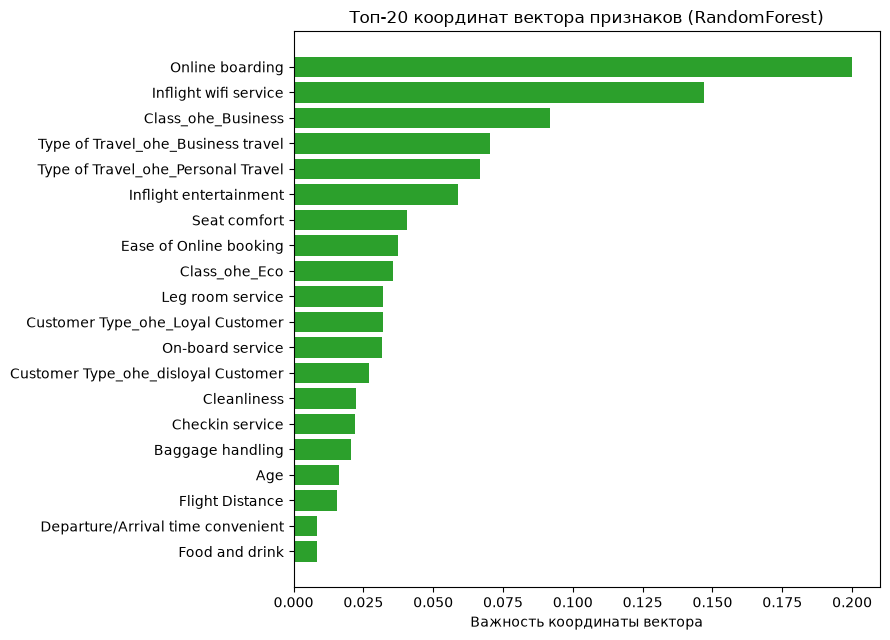


Топ-10 важных координат:
  Online boarding: 0.2000
  Inflight wifi service: 0.1471
  Class_ohe_Business: 0.0919
  Type of Travel_ohe_Business travel: 0.0704
  Type of Travel_ohe_Personal Travel: 0.0668
  Inflight entertainment: 0.0588
  Seat comfort: 0.0405
  Ease of Online booking: 0.0374
  Class_ohe_Eco: 0.0357
  Leg room service: 0.0322


In [43]:
sample = best_model.transform(air_valid.limit(1))

meta = sample.schema["features"].metadata
attrs = meta.get("ml_attr", {}).get("attrs", {})

pairs = []
for kind in ("numeric", "nominal", "binary"):
    for a in attrs.get(kind, []):
        pairs.append((a["idx"], a["name"]))
pairs.sort()

feature_names_full = [name for _, name in pairs]
print(f"Найдено координат в метаданных: {len(feature_names_full)}")

rf_stage = best_model.stages[-1]
importances = rf_stage.featureImportances.toArray()
print(f"Длина вектора importances: {len(importances)}")

assert len(feature_names_full) == len(importances), "Рассинхрон имён и важностей"

order = np.argsort(importances)[::-1][:20]

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh([feature_names_full[i] for i in order][::-1], importances[order][::-1], color="tab:green")
ax.set_xlabel("Важность координаты вектора")
ax.set_title("Топ-20 координат вектора признаков (RandomForest)")
plt.tight_layout()
plt.savefig(OUT / "test_feature_importance.png", dpi=160)
plt.show()

print("\nТоп-10 важных координат:")
for i in order[:10]:
    print(f"  {feature_names_full[i]}: {importances[i]:.4f}")

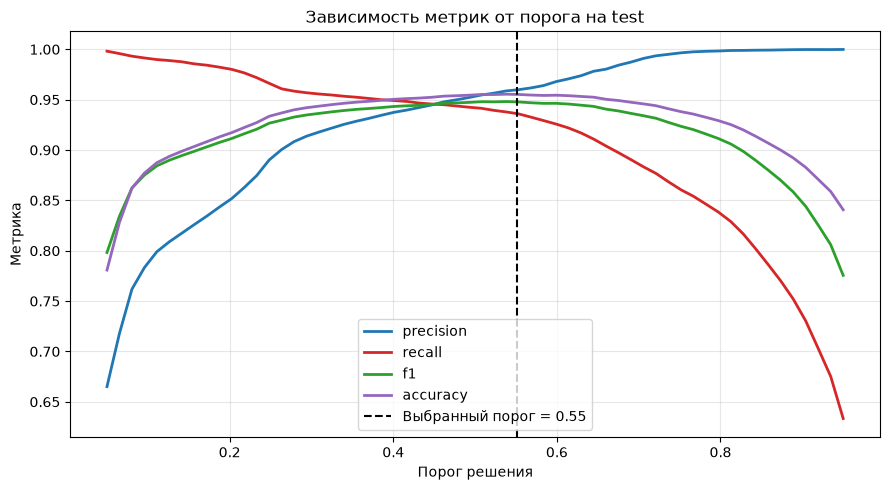

In [44]:
thresholds_sweep = np.linspace(0.05, 0.95, 60)
metrics_sweep = []
for t in thresholds_sweep:
    m = binary_metrics(test_scores, threshold=t, ranking=False)
    metrics_sweep.append({"threshold": t, **m})

sweep_df = pd.DataFrame(metrics_sweep)

fig, ax = plt.subplots(figsize=(9, 5))
for col, color in [("precision", "tab:blue"),
                   ("recall", "tab:red"),
                   ("f1", "tab:green"),
                   ("accuracy", "tab:purple")]:
    ax.plot(sweep_df["threshold"], sweep_df[col], label=col, color=color, linewidth=2)
ax.axvline(BEST_THRESHOLD, linestyle="--", color="black", label=f"Выбранный порог = {BEST_THRESHOLD:.2f}")
ax.set(xlabel="Порог решения", ylabel="Метрика", title="Зависимость метрик от порога на test")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "test_threshold_sweep.png", dpi=160)
plt.show()

In [45]:
from pyspark.ml import PipelineModel
import json

best_model.write().overwrite().save((OUT / "airline_classifier").as_posix())

config = {
    "seed": SEED,
    "task": "binary_classification",
    "dataset": "Airline Satisfaction Data",
    "n_train": 77927,
    "n_valid": 25976,
    "n_test": 25977,
    "best_model": best_name,
    "threshold": round(BEST_THRESHOLD, 4),
    "feature_count": len(feature_names_full),
    "test_pr_auc": round(test_metrics["areaUnderPR"], 4),
    "test_roc_auc": round(test_metrics["areaUnderROC"], 4),
    "test_f1_at_threshold": round(test_metrics["f1"], 4),
    "spark_version": spark.version,
}
(OUT / "airline_config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")

print(json.dumps(config, ensure_ascii=False, indent=2))

{
  "seed": 42,
  "task": "binary_classification",
  "dataset": "Airline Satisfaction Data",
  "n_train": 77927,
  "n_valid": 25976,
  "n_test": 25977,
  "best_model": "RF(trees=100, depth=12)",
  "threshold": 0.5515,
  "feature_count": 33,
  "test_pr_auc": 0.9901,
  "test_roc_auc": 0.9911,
  "test_f1_at_threshold": 0.9479,
  "spark_version": "4.2.0"
}


## Очистка и остановка

In [46]:
final_summary = {
    "task": "Binary classification — airline passenger satisfaction",
    "dataset": "Airline Satisfaction Data",
    "n_rows_total": 129880,
    "n_features": len(feature_names_full),
    "split": {"train": 77927, "valid": 25976, "test": 25977},
    "scenarios": {
        "A_with_delay": "признак Departure Delay включён (основной)",
        "B_without_delay": "задержка исключена (абляция)",
    },
    "baseline_constant": {
        "accuracy": 0.5655,
        "pr_auc": 0.4345,
    },
    "baseline_rule_by_class": {
        "accuracy": 0.7507,
        "precision": 0.6935,
        "recall": 0.7639,
        "f1": 0.7270,
        "pr_auc": 0.6610,
    },
    "models_valid": val_table.to_dict(orient="records"),
    "best_model": best_name,
    "best_threshold": round(BEST_THRESHOLD, 4),
    "test_metrics": {
        "accuracy": round(test_metrics["accuracy"], 4),
        "precision": round(test_metrics["precision"], 4),
        "recall": round(test_metrics["recall"], 4),
        "f1": round(test_metrics["f1"], 4),
        "roc_auc": round(test_metrics["areaUnderROC"], 4),
        "pr_auc": round(test_metrics["areaUnderPR"], 4),
        "tp": test_metrics["tp"],
        "fp": test_metrics["fp"],
        "fn": test_metrics["fn"],
        "tn": test_metrics["tn"],
    },
    "ablation_without_delay_pr_auc": round(binary_metrics(pred_no_delay)["areaUnderPR"], 4),
    "top10_features": [
        {"name": feature_names_full[i], "importance": float(importances[i])}
        for i in order[:10]
    ],
    "spark_version": spark.version,
}

(OUT / "part2_summary.json").write_text(
    json.dumps(final_summary, ensure_ascii=False, indent=2), encoding="utf-8")

print(json.dumps(final_summary, ensure_ascii=False, indent=2))
print(f"\nСохранено в {OUT / 'part2_summary.json'}")

{
  "task": "Binary classification — airline passenger satisfaction",
  "dataset": "Airline Satisfaction Data",
  "n_rows_total": 129880,
  "n_features": 33,
  "split": {
    "train": 77927,
    "valid": 25976,
    "test": 25977
  },
  "scenarios": {
    "A_with_delay": "признак Departure Delay включён (основной)",
    "B_without_delay": "задержка исключена (абляция)"
  },
  "baseline_constant": {
    "accuracy": 0.5655,
    "pr_auc": 0.4345
  },
  "baseline_rule_by_class": {
    "accuracy": 0.7507,
    "precision": 0.6935,
    "recall": 0.7639,
    "f1": 0.727,
    "pr_auc": 0.661
  },
  "models_valid": [
    {
      "model": "RF(trees=100, depth=12)",
      "fit_s": 61.7,
      "accuracy": 0.9499923005851555,
      "precision": 0.9491769362238014,
      "recall": 0.9349636718057771,
      "f1": 0.942016694192742,
      "tp": 10552,
      "fp": 565,
      "fn": 734,
      "tn": 14125,
      "areaUnderROC": 0.9895895949691944,
      "areaUnderPR": 0.9883668660683421
    },
    {
      

In [47]:
cached_dfs = [
    "air_split", "air_train", "air_valid", "air_test",
    "baseline_constant", "baseline_class",
    "test_scores", "best_pred_valid", "pred_no_delay",
]

for name in cached_dfs:
    df = globals().get(name)
    if df is not None and hasattr(df, "unpersist"):
        try:
            df.unpersist()
            print(f"unpersist OK: {name}")
        except Exception as e:
            print(f"unpersist FAIL: {name}: {e}")
    else:
        print(f"skip: {name}")

unpersist OK: air_split
unpersist OK: air_train
unpersist OK: air_valid
unpersist OK: air_test
unpersist OK: baseline_constant
unpersist OK: baseline_class
unpersist OK: test_scores
unpersist OK: best_pred_valid
unpersist OK: pred_no_delay


In [48]:
print("Spark UI (работает до следующей строки):", sc.uiWebUrl)
spark.stop()
print("SparkSession остановлена. Работа завершена.")

Spark UI (работает до следующей строки): http://MSI:4040
SparkSession остановлена. Работа завершена.
